# BBTD: one matrix per pixel (ALS)

When every pixel holds a **matrix** (for example a K × M map of measurements), the data
form a fourth-order tensor of shape (rows, columns, K, M). The **BBTD** model writes it as
a sum of terms *spatial map × matrix*, where the map has rank L1 and the matrix has
rank L2 (see [BBTD](../models/bbtd.md)).

This tutorial uses the unconstrained ALS solver: maps and matrices can take any sign.
For covariance images, see the [constrained version](bbtd-admm.ipynb).

## The data

20 × 25 pixels, each with a 10 × 10 matrix. There are R = 2 terms with spatial maps of
rank L1 = 5 and matrices of rank L2 = 2. The true factors are random, and we add 1% noise.

In [1]:
import numpy as np

from pybbtd import BBTD
from pybbtd.bbtd import factors_to_tensor
from pybbtd.visualization import plot_error

np.random.seed(0)
R, L1, L2 = 2, 5, 2
model = BBTD((20, 25, 10, 10), R=R, L1=L1, L2=L2)

A0 = np.random.randn(20, L1 * R)  # spatial map of term r: A0_r @ B0_r.T
B0 = np.random.randn(25, L1 * R)
C0 = np.random.randn(10, L2 * R)  # matrix of term r: C0_r @ D0_r.T
D0 = np.random.randn(10, L2 * R)
phi, psi = model.get_constraint_matrices()
T0 = factors_to_tensor(A0, B0, C0, D0, phi, psi)
T = T0 + 0.01 * np.linalg.norm(T0) / np.sqrt(T0.size) * np.random.randn(*T0.shape)

## Fit the model

In [2]:
model.check_uniqueness()

True

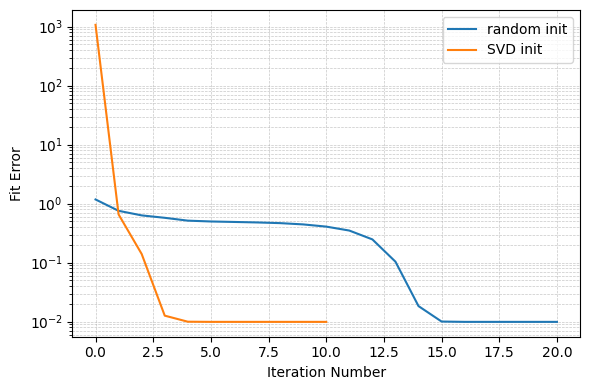

In [3]:
model.fit(T, algorithm="ALS", init="random", max_iter=1000, rel_tol=1e-10, abs_tol=0)
random_init_error = model.fit_error

model.fit(T, algorithm="ALS", init="svd", max_iter=1000, rel_tol=1e-10, abs_tol=0)
svd_init_error = model.fit_error

plot_error([random_init_error, svd_init_error], labels=["random init", "SVD init"])

## Check the result

The fitted tensor is closer to the clean tensor `T0` than the noisy data are (1% away):

In [4]:
A, B, C, D = model.factors
np.linalg.norm(model.tensor - T0) / np.linalg.norm(T0)

np.float64(0.0010103973358921495)